In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/refs/heads/master/IMDB-Dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset loaded successfully!
Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [3]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)       # Remove HTML tags
    text = re.sub(r"http\S+|www\S+", " ", text)  # Remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)   # Keep letters and spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df.dropna(subset=["review", "sentiment"]).copy()
df["clean_review"] = df["review"].apply(clean_text)

display(df[["review", "clean_review", "sentiment"]].head())
print("Total usable reviews:", len(df))

,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive


Total usable reviews: 50000


In [4]:
X = df["clean_review"]
y = df["sentiment"].str.lower().str.strip()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 40000
Testing reviews: 10000


In [5]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training feature matrix: (40000, 5000)
Testing feature matrix: (10000, 5000)


In [6]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000)
}

results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

    print("\n", name)
    print(classification_report(y_test, predictions, zero_division=0))


 Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative       0.86      0.85      0.85      5000
    positive       0.85      0.86      0.86      5000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000


 Logistic Regression
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      5000
    positive       0.88      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



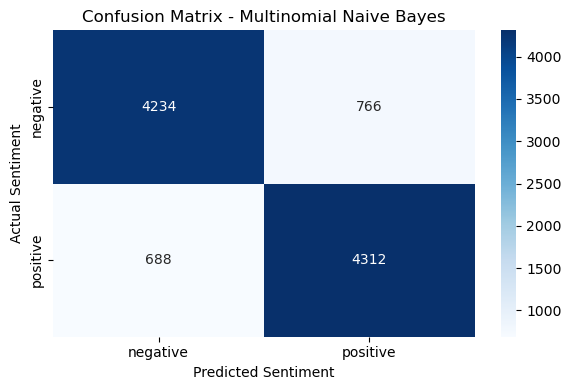

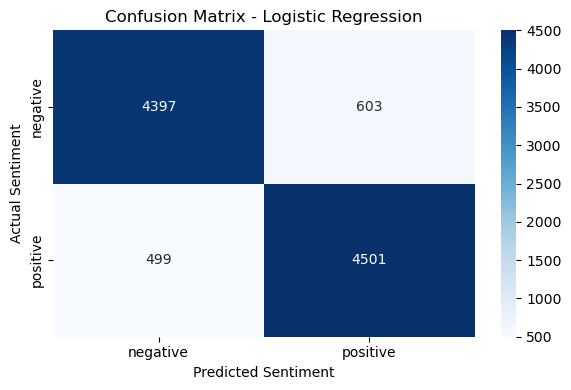

In [7]:
for name, model in models.items():
    predictions = model.predict(X_test_tfidf)
    labels = model.classes_

    cm = confusion_matrix(y_test, predictions, labels=labels)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.tight_layout()
    plt.show()

                  Model  Accuracy  Precision  Recall  F1-score
Multinomial Naive Bayes     0.855      0.855   0.855     0.855
    Logistic Regression     0.890      0.890   0.890     0.890


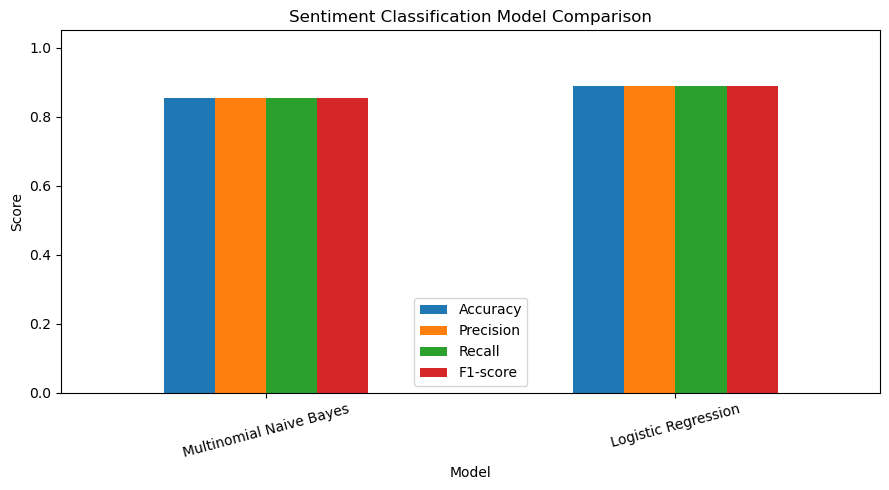

In [8]:
results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

results_df.set_index("Model").plot(
    kind="bar",
    ylim=(0, 1.05),
    figsize=(9, 5)
)

plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [9]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)
    review_tfidf = tfidf.transform([cleaned_review])

    predictions = {}

    for name, model in models.items():
        predictions[name] = model.predict(review_tfidf)[0]

    return predictions


# Test with custom reviews
print(predict_sentiment("This product is amazing and I love it!"))
print(predict_sentiment("Very bad quality. I hate this product."))

{'Multinomial Naive Bayes': np.str_('positive'), 'Logistic Regression': 'positive'}
{'Multinomial Naive Bayes': np.str_('negative'), 'Logistic Regression': 'negative'}


In [ ]:
my_review = input("Enter a customer review: ")
print("Predictions:", predict_sentiment(my_review))